# Compare WERM against McScan for dense (and slightly correlated) signals

In [ ]:
from WERM.config import unif_prior_to_η_ϕ, unif_prior_to_η_ϕ_combinations
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
from WERM.model import *
from WERM.M_est_fixed_point_eqns import *
import WERM
import WERM.gof
import WERM.performance_measures
import WERM.comparison
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
import time
tqdm = partial(tqdm, position=0, leave=True)

np.random.seed(10)

p = 250
L = 3 # num signals. L-1 changepoints

δ_list = [2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]
noise_std = 0.5
num_trials = 10

fractional_chgpt_locations = np.array([0.3, 0.7])
# fractional_chgpt_locations = np.array([0.5])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

erm_corr_arr = np.zeros((len(δ_list), num_trials, L))
erm_MSE_arr= np.zeros((len(δ_list), num_trials, L))
ERM_haus_arr = np.zeros((len(δ_list), num_trials))
ERM_size_arr = np.zeros((len(δ_list), num_trials))
ERM_runtime = np.zeros((len(δ_list), num_trials))
DCDP_haus_arr = np.zeros((len(δ_list), num_trials))
DCDP_size_arr = np.zeros((len(δ_list), num_trials))
McScan_haus_arr = np.zeros((len(δ_list), num_trials))
McScan_size_arr = np.zeros((len(δ_list), num_trials))
McScan_runtime = np.zeros((len(δ_list), num_trials))

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # --- Preliminaries ---
    # Changepoint locations
    # Changepoint locations
    Δ = lambda n: int(n/10)

    # For estimating size
    Lmin = 1
    Lmax = L
    p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    # p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ_combinations(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix

    # For estimating location
    # Lmin = L
    # Lmax = L
    # p_l = None
    # num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix

    ϕ_normalized = ϕ / ϕ.sum(axis = 1)[:, None]
    plt.plot(ϕ_normalized.T)
    plt.show()
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    # Subsampling
    # subsample_factor = 1
    # n_subsampled = int(n/subsample_factor)
    # _, η_arr_subsampled, p_η_arr_subsampled, _ = unif_prior_to_η_ϕ_combinations(Lmin, Lmax, Δ(n_subsampled), n_subsampled, p_l = p_l) # Lxn matrix
    # # _, η_arr_subsampled, p_η_arr_subsampled, _ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n_subsampled), n_subsampled, p_l = p_l) # Lxn matrix
    # η_arr_subsampled = η_arr_subsampled * subsample_factor # Rescale η_arr_subsampled to match η_arr

    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    if fractional_chgpt_locations.size == 0:
        # No chgpt prior
        for ℓ_ in range(L):
            ϕ[ℓ_, :] = np.ones(n)

    # Generate a non-identity covariance matrix
    Σ = np.zeros((p, p))
    for i_ in range(p):
        for j_ in range(p):
            Σ[i_, j_] = 0.25 ** (np.abs(i_ - j_))
    L_chol = scipy.linalg.cholesky(Σ, lower = True)

    # Gaussian Signal Prior
    γ_squared_over_δ = 8
    # Design a non-trivial LxL covariance
    covvy = np.zeros((L, L))
    for i_ in range(L):
        for j_ in range(L):
            covvy[i_, j_] = 0.25 ** (np.abs(i_ - j_))
    # covvy = np.block([[1, 0.4], [0.4, 1]])
    B̃_cov = γ_squared_over_δ * δ * covvy # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃
    print("ρ: ", ρ)

    for trial_num in tqdm(range(num_trials)): 

        # Generate the observation vector Y
        X = np.random.normal(0, np.sqrt(1/n), (n, p)) @ L_chol.T

        Θ = X @ B̃
        y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()

        # --- Run Weighted ERM --- #
        B̂_erm = np.zeros((p, L))
        β̂_erm_list = [None for ℓ_ in range(L)]

        # Time the execution of the ERM and save it
        start_time_ERM = time.time()
        for ℓ_ in range(L): 
            π = ϕ[ℓ_, :]

            print("Regressing on signal ", ℓ_)
            sample_weight = π
            sk_lin_reg = linear_model.LinearRegression(n_jobs = 2, fit_intercept = False)
            sk_lin_reg.fit(X, y, sample_weight = sample_weight)
            print("Done regressing on signal.")
            β̂_erm = sk_lin_reg.coef_
            β̂_erm_list[ℓ_] = β̂_erm

            ### --- Compute norm squared correlation --- ###
            B̂_erm[:, ℓ_] = β̂_erm
            erm_corr_arr[i, trial_num, ℓ_] = (WERM.norm_sq_corr(β̂_erm, B̃[:, ℓ_])) # For ERM compute once

            ### --- Compute MSE --- ###
            erm_MSE_arr[i, trial_num, ℓ_] = (WERM.MSE(β̂_erm.flatten(), B̃[:, ℓ_]))

        ## Compute Chgpt estimate for WERM
        PAL = ['#e66101', '#fdb863', '#f7f7f7', '#b2abd2', '#5e3c99']
        for ℓ in range(L):
            plt.plot(np.arange(n), (ζ(X @ B̂_erm[:, ℓ]) - np.multiply(y.flatten(), X @ B̂_erm[:, ℓ])), c = PAL[-1 - ℓ_], alpha = 0.5, label="ERM β̂" + str(ℓ))

        print("Optimizing gof erm...")
        opt_chgpt_loc_erm = WERM.gof.lin_reg_opt_chgpt_gof(X @ B̂_erm, y, η_arr, p_η_arr, σ = noise_std, ϵ = 0.005)
        print("WERM chpt estimate: ", opt_chgpt_loc_erm)
        print("Done optimizing gof erm.")
        
        # Save the runtime
        ERM_runtime[i, trial_num] = time.time() - start_time_ERM

        # plot a vertical line at the optimal changepoint location
        [plt.axvline(x=loc, color='r', linestyle='-.', alpha = 0.8, label="ERM chgpt") for loc in opt_chgpt_loc_erm]
        [plt.axvline(x=c, color='g', linestyle='--', alpha = 0.8, label="True") for c in true_chgpt_locations(n)]

        ERM_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(opt_chgpt_loc_erm, true_chgpt_locations(n)))
        ERM_size_arr[i, trial_num] = (len(opt_chgpt_loc_erm[opt_chgpt_loc_erm != -1]))

        ### --- Run DCDP, and record the runtime --- ###
        # print("Running DCDP...")
        # DCDP_res = np.array(WERM.comparison.DCDP(X, np.array(y), λ_list = [0.1, 1, 5, 10], γ_list = [100, 500, 1000]))
        # print("DCDP_res: ", DCDP_res)
        # # plot a vertical line at the DCDP estimated change point location
        # [plt.axvline(x=loc, color = 'b', linestyle='-.', alpha = 0.8, label="DCDP chgpt") for loc in DCDP_res]
        # DCDP_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(DCDP_res, true_chgpt_locations(n)))
        # DCDP_size_arr[i, trial_num] = (len(DCDP_res[DCDP_res != -1]))

        ### --- Run McScan --- ###
        start_time_McScan = time.time()
        print("Running McScan...")
        try: 
            McScan_res = np.array(WERM.comparison.run_mcscan(X, np.array(y).reshape(-1, 1)))
        except:
            McScan_res = np.array([-1])
        print("McScan_res: ", McScan_res)
        McScan_runtime[i, trial_num] = time.time() - start_time_McScan
        # plot a vertical line at the McScan estimated change point location
        [plt.axvline(x=loc, color='c', linestyle='-.', alpha = 0.8, label="McScan chgpt") for loc in McScan_res]
        McScan_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(McScan_res, true_chgpt_locations(n)))
        McScan_size_arr[i, trial_num] = (len(McScan_res[McScan_res != -1]))

        plt.legend()
        plt.show()

PAL = ['#1b9e77','#d95f02','#7570b3','#e7298a']
# Sqcorr plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_corr_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# MSE plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_MSE_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
# plt.ylim((0, 2))
plt.xlabel("δ")
plt.ylabel("MSE")
plt.legend()
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(ERM_haus_arr, axis = 1), yerr = np.std(ERM_haus_arr, axis = 1), label="ERM", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
# plt.errorbar(δ_list, np.mean(DCDP_haus_arr, axis = 1), yerr = np.std(DCDP_haus_arr, axis = 1), label="DCDP", marker="o", ls="-.", c=PAL[1], alpha = 1.0)
plt.errorbar(δ_list, np.mean(McScan_haus_arr, axis = 1), yerr = np.std(McScan_haus_arr, axis = 1), label="McScan", marker="o", ls="-.", c=PAL[2], alpha = 1.0)
# plt.scatter(δ_arr, ERM_haus_arr, label="ERM", marker="x", c=PAL[1], alpha = 0.2)
# plt.scatter(δ_arr, AMP_haus_arr, label="AMP", marker="o", c=PAL[0], alpha = 0.2)
plt.ylim((0, 0.35))
plt.xlabel("δ")
plt.ylabel("Hausdorff")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(ERM_size_arr, axis = 1), yerr = np.std(ERM_haus_arr, axis = 1), label="ERM", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
# plt.errorbar(δ_list, np.mean(DCDP_size_arr, axis = 1), yerr = np.std(DCDP_haus_arr, axis = 1), label="DCDP", marker="o", ls="-.", c=PAL[1], alpha = 1.0)
plt.errorbar(δ_list, np.mean(McScan_size_arr, axis = 1), yerr = np.std(McScan_haus_arr, axis = 1), label="McScan", marker="o", ls="-.", c=PAL[2], alpha = 1.0)
# plt.scatter(δ_arr, ERM_haus_arr, label="ERM", marker="x", c=PAL[1], alpha = 0.2)
# plt.scatter(δ_arr, AMP_haus_arr, label="AMP", marker="o", c=PAL[0], alpha = 0.2)
plt.ylim((0, L + 1))
plt.xlabel("δ")
plt.ylabel("Size")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Runtime plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(ERM_runtime, axis = 1), yerr = np.std(ERM_runtime, axis = 1), label="ERM", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
plt.errorbar(δ_list, np.mean(McScan_runtime, axis = 1), yerr = np.std(McScan_runtime, axis = 1), label="McScan", marker="o", ls="-.", c=PAL[2], alpha = 1.0)
plt.xlabel("δ")
plt.ylabel("Runtime")
plt.legend()
plt.show()

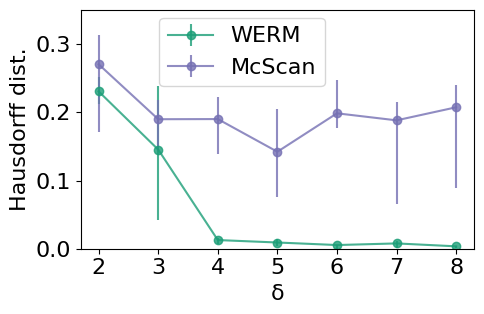

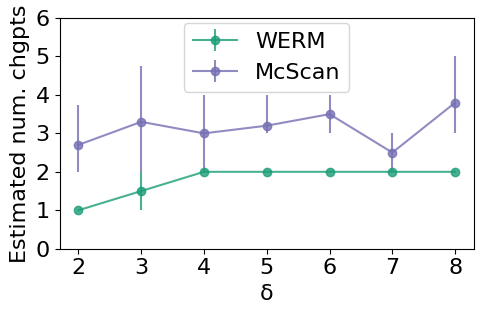

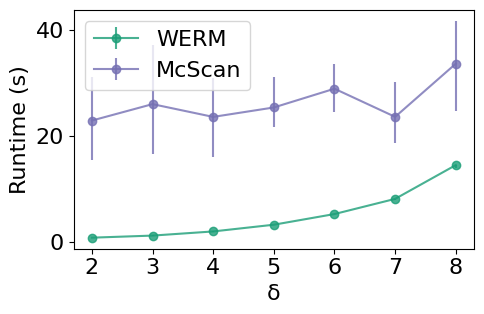

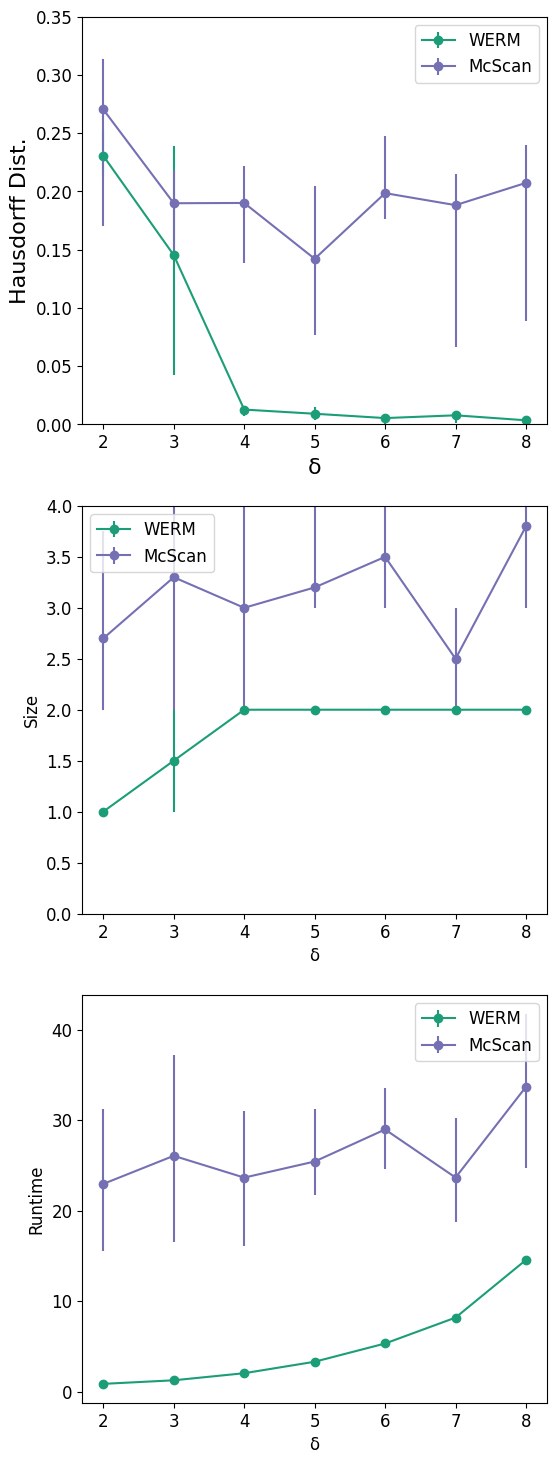

In [52]:
# Save the results
np.save("results/linear_model_comparison/McScan_dense_signal_comparison/erm_corr_arr.npy", erm_corr_arr)
np.save("results/linear_model_comparison/McScan_dense_signal_comparison/erm_MSE_arr.npy", erm_MSE_arr)
np.save("results/linear_model_comparison/McScan_dense_signal_comparison/ERM_haus_arr.npy", ERM_haus_arr)
np.save("results/linear_model_comparison/McScan_dense_signal_comparison/ERM_size_arr.npy", ERM_size_arr)
np.save("results/linear_model_comparison/McScan_dense_signal_comparison/ERM_runtime.npy", ERM_runtime)
np.save("results/linear_model_comparison/McScan_dense_signal_comparison/DCDP_haus_arr.npy", DCDP_haus_arr)
np.save("results/linear_model_comparison/McScan_dense_signal_comparison/DCDP_size_arr.npy", DCDP_size_arr)
np.save("results/linear_model_comparison/McScan_dense_signal_comparison/McScan_haus_arr.npy", McScan_haus_arr)
np.save("results/linear_model_comparison/McScan_dense_signal_comparison/McScan_size_arr.npy", McScan_size_arr)
np.save("results/linear_model_comparison/McScan_dense_signal_comparison/McScan_runtime.npy", McScan_runtime)

### --- Prepare asymmetric error bars for matplotlib, and ensure that the error bars are not negative --- ###
ERM_lower_err = np.mean(ERM_haus_arr, axis = 1) - np.percentile(ERM_haus_arr, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_haus_arr, 75, axis = 1) - np.mean(ERM_haus_arr, axis = 1)
ERM_haus_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_haus_asymmetric_err[0][ERM_haus_asymmetric_err[0] < 0] = 0
ERM_haus_asymmetric_err[1][ERM_haus_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_haus_arr, axis = 1) - np.percentile(McScan_haus_arr, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_haus_arr, 75, axis = 1) - np.mean(McScan_haus_arr, axis = 1)
McScan_haus_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_haus_asymmetric_err[0][McScan_haus_asymmetric_err[0] < 0] = 0
McScan_haus_asymmetric_err[1][McScan_haus_asymmetric_err[1] < 0] = 0

ERM_lower_err = np.mean(ERM_size_arr, axis = 1) - np.percentile(ERM_size_arr, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_size_arr, 75, axis = 1) - np.mean(ERM_size_arr, axis = 1)
ERM_size_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_size_asymmetric_err[0][ERM_size_asymmetric_err[0] < 0] = 0
ERM_size_asymmetric_err[1][ERM_size_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_size_arr, axis = 1) - np.percentile(McScan_size_arr, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_size_arr, 75, axis = 1) - np.mean(McScan_size_arr, axis = 1)
McScan_size_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_size_asymmetric_err[0][McScan_size_asymmetric_err[0] < 0] = 0
McScan_size_asymmetric_err[1][McScan_size_asymmetric_err[1] < 0] = 0

ERM_lower_err = np.mean(ERM_runtime, axis = 1) - np.percentile(ERM_runtime, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_runtime, 75, axis = 1) - np.mean(ERM_runtime, axis = 1)
ERM_runtime_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_runtime_asymmetric_err[0][ERM_runtime_asymmetric_err[0] < 0] = 0
ERM_runtime_asymmetric_err[1][ERM_runtime_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_runtime, axis = 1) - np.percentile(McScan_runtime, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_runtime, 75, axis = 1) - np.mean(McScan_runtime, axis = 1)
McScan_runtime_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_runtime_asymmetric_err[0][McScan_runtime_asymmetric_err[0] < 0] = 0
McScan_runtime_asymmetric_err[1][McScan_runtime_asymmetric_err[1] < 0] = 0

### --- Replot the figures individually --- ###
δ_arr = np.array([δ_list for _ in range(num_trials)])
# Hausdorff plots
fig = plt.figure(figsize = (5, 3.3))
cmap = plt.get_cmap('RdBu')
plt.rcParams.update({'font.size': 12})
plt.errorbar(δ_list, np.mean(ERM_haus_arr, axis = 1), yerr = ERM_haus_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 0.8)
plt.errorbar(δ_list, np.mean(McScan_haus_arr, axis = 1), yerr = McScan_haus_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 0.8)
plt.ylim((0, 0.35))
plt.xlabel("δ", fontsize=16)
plt.ylabel("Hausdorff dist.", fontsize=16)
plt.xticks(fontsize=16)
plt.yticks([0, 0.1, 0.2, 0.3], fontsize=16)
plt.legend(prop={'size': 16}, loc = (0.2, 0.68))
fig.tight_layout()
plt.savefig("figures/linear_model_comparison/McScan_dense_signal_comparison/linear_model_comparison_haus" + str(L) + "_Lstar" + str(fractional_chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Size plots
fig = plt.figure(figsize = (5, 3.3))
cmap = plt.get_cmap('RdBu')
plt.rcParams.update({'font.size': 12})
plt.errorbar(δ_list, np.mean(ERM_size_arr, axis = 1), yerr = ERM_size_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 0.8)
plt.errorbar(δ_list, np.mean(McScan_size_arr, axis = 1), yerr = McScan_size_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 0.8)
plt.ylim((0, L + 3))
plt.xlabel("δ", fontsize=16)
plt.ylabel("Estimated num. chgpts", fontsize=16)
plt.legend(prop={'size': 16}, loc = (0.3, 0.68))
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
fig.tight_layout()
plt.savefig("figures/linear_model_comparison/McScan_dense_signal_comparison/linear_model_comparison_size" + str(L) + "_Lstar" + str(fractional_chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Runtime plots
fig = plt.figure(figsize = (5, 3.3))
cmap = plt.get_cmap('RdBu')
plt.rcParams.update({'font.size': 12})
plt.errorbar(δ_list, np.mean(ERM_runtime, axis = 1), yerr = ERM_runtime_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 0.8)
plt.errorbar(δ_list, np.mean(McScan_runtime, axis = 1), yerr = McScan_runtime_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 0.8)
plt.xlabel("δ", fontsize=16)
plt.ylabel("Runtime (s)", fontsize=16)
plt.legend(prop={'size': 16})
plt.xticks(fontsize=16)
plt.yticks([0, 20, 40], fontsize=16)
fig.tight_layout()
plt.savefig("figures/linear_model_comparison/McScan_dense_signal_comparison/linear_model_comparison_runtime" + str(L) + "_Lstar" + str(fractional_chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Plot the above three figures on top of each other as subplots
fig, axs = plt.subplots(3, 1, figsize=(6, 18))

# Hausdorff estimation plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
axs[0].errorbar(δ_list, np.mean(ERM_haus_arr, axis = 1), yerr = ERM_haus_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 1.0)
axs[0].errorbar(δ_list, np.mean(McScan_haus_arr, axis = 1), yerr = McScan_haus_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 1.0)
axs[0].set_ylim((0, 0.35))
axs[0].set_xlabel("δ", fontsize=16)
axs[0].set_ylabel("Hausdorff Dist.", fontsize=16)
axs[0].legend()

# Hausdorff size plots
axs[1].errorbar(δ_list, np.mean(ERM_size_arr, axis = 1), yerr = ERM_size_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 1.0)
axs[1].errorbar(δ_list, np.mean(McScan_size_arr, axis = 1), yerr = McScan_size_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 1.0)
axs[1].set_ylim((0, L + 1))
axs[1].set_xlabel("δ")
axs[1].set_ylabel("Size")
axs[1].legend()

# Runtime plots
axs[2].errorbar(δ_list, np.mean(ERM_runtime, axis = 1), yerr = ERM_runtime_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 1.0)
axs[2].errorbar(δ_list, np.mean(McScan_runtime, axis = 1), yerr = McScan_runtime_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 1.0)
axs[2].set_xlabel("δ")
axs[2].set_ylabel("Runtime")
axs[2].legend()
plt.savefig("figures/linear_model_comparison/McScan_dense_signal_comparison/linear_model_comparison.pdf")

# Save the figure as a tikz file, and use a workaround to make the legend work
import tikzplotlib
def tikzplotlib_fix_ncols(obj):
    """
    workaround for matplotlib 3.6 renamed legend's _ncol to _ncols, which breaks tikzplotlib
    """
    if hasattr(obj, "_ncols"):
        obj._ncol = obj._ncols
    for child in obj.get_children():
        tikzplotlib_fix_ncols(child)
tikzplotlib_fix_ncols(fig)
tikzplotlib.save("figures/linear_model_comparison/McScan_dense_signal_comparison/linear_model_comparison.tex")


plt.show()



### Load results and replot

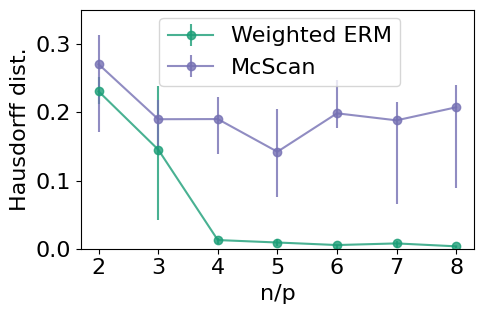

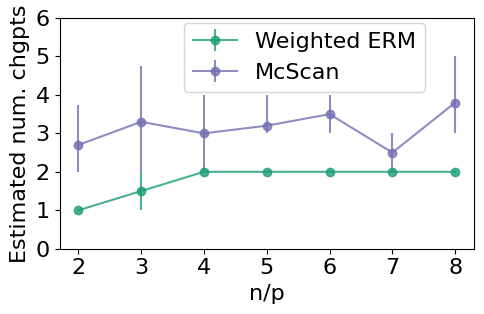

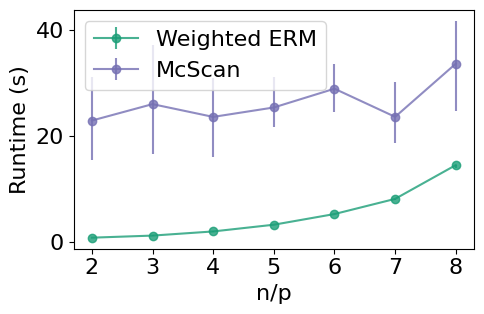

In [34]:
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import numpy.random as nprandom
import matplotlib.pyplot as plt
from functools import partial
tqdm = partial(tqdm, position=0, leave=True)

# Load the results and replot
erm_corr_arr = np.load("results/linear_model_comparison/McScan_dense_signal_comparison/erm_corr_arr.npy")
erm_MSE_arr = np.load("results/linear_model_comparison/McScan_dense_signal_comparison/erm_MSE_arr.npy")
ERM_haus_arr = np.load("results/linear_model_comparison/McScan_dense_signal_comparison/ERM_haus_arr.npy")
ERM_size_arr = np.load("results/linear_model_comparison/McScan_dense_signal_comparison/ERM_size_arr.npy")
ERM_runtime = np.load("results/linear_model_comparison/McScan_dense_signal_comparison/ERM_runtime.npy")
DCDP_haus_arr = np.load("results/linear_model_comparison/McScan_dense_signal_comparison/DCDP_haus_arr.npy")
DCDP_size_arr = np.load("results/linear_model_comparison/McScan_dense_signal_comparison/DCDP_size_arr.npy")
McScan_haus_arr = np.load("results/linear_model_comparison/McScan_dense_signal_comparison/McScan_haus_arr.npy")
McScan_size_arr = np.load("results/linear_model_comparison/McScan_dense_signal_comparison/McScan_size_arr.npy")
McScan_runtime = np.load("results/linear_model_comparison/McScan_dense_signal_comparison/McScan_runtime.npy")

### --- Prepare asymmetric error bars for matplotlib, and ensure that the error bars are not negative --- ###
ERM_lower_err = np.mean(ERM_haus_arr, axis = 1) - np.percentile(ERM_haus_arr, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_haus_arr, 75, axis = 1) - np.mean(ERM_haus_arr, axis = 1)
ERM_haus_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_haus_asymmetric_err[0][ERM_haus_asymmetric_err[0] < 0] = 0
ERM_haus_asymmetric_err[1][ERM_haus_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_haus_arr, axis = 1) - np.percentile(McScan_haus_arr, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_haus_arr, 75, axis = 1) - np.mean(McScan_haus_arr, axis = 1)
McScan_haus_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_haus_asymmetric_err[0][McScan_haus_asymmetric_err[0] < 0] = 0
McScan_haus_asymmetric_err[1][McScan_haus_asymmetric_err[1] < 0] = 0

ERM_lower_err = np.mean(ERM_size_arr, axis = 1) - np.percentile(ERM_size_arr, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_size_arr, 75, axis = 1) - np.mean(ERM_size_arr, axis = 1)
ERM_size_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_size_asymmetric_err[0][ERM_size_asymmetric_err[0] < 0] = 0
ERM_size_asymmetric_err[1][ERM_size_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_size_arr, axis = 1) - np.percentile(McScan_size_arr, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_size_arr, 75, axis = 1) - np.mean(McScan_size_arr, axis = 1)
McScan_size_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_size_asymmetric_err[0][McScan_size_asymmetric_err[0] < 0] = 0
McScan_size_asymmetric_err[1][McScan_size_asymmetric_err[1] < 0] = 0

ERM_lower_err = np.mean(ERM_runtime, axis = 1) - np.percentile(ERM_runtime, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_runtime, 75, axis = 1) - np.mean(ERM_runtime, axis = 1)
ERM_runtime_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_runtime_asymmetric_err[0][ERM_runtime_asymmetric_err[0] < 0] = 0
ERM_runtime_asymmetric_err[1][ERM_runtime_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_runtime, axis = 1) - np.percentile(McScan_runtime, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_runtime, 75, axis = 1) - np.mean(McScan_runtime, axis = 1)
McScan_runtime_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_runtime_asymmetric_err[0][McScan_runtime_asymmetric_err[0] < 0] = 0
McScan_runtime_asymmetric_err[1][McScan_runtime_asymmetric_err[1] < 0] = 0

### --- Pre-load the existing parameters --- ###

np.random.seed(10)

p = 250
L = 3 # num signals. L-1 changepoints

δ_list = [2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]
noise_std = 0.5
num_trials = 10

fractional_chgpt_locations = np.array([0.3, 0.7])


### --- Replot the figures individually --- ###
δ_arr = np.array([δ_list for _ in range(num_trials)])
# Hausdorff plots
fig = plt.figure(figsize = (5, 3.3))
cmap = plt.get_cmap('RdBu')
plt.rcParams.update({'font.size': 12})
plt.errorbar(δ_list, np.mean(ERM_haus_arr, axis = 1), yerr = ERM_haus_asymmetric_err, label="Weighted ERM", marker="o", ls="-", c=PAL[0], alpha = 0.8)
plt.errorbar(δ_list, np.mean(McScan_haus_arr, axis = 1), yerr = McScan_haus_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 0.8)
plt.ylim((0, 0.35))
plt.xlabel("n/p", fontsize=16)
plt.ylabel("Hausdorff dist.", fontsize=16)
plt.xticks(fontsize=16)
plt.yticks([0, 0.1, 0.2, 0.3], fontsize=16)
plt.legend(prop={'size': 16}, loc = (0.2, 0.68))
fig.tight_layout()
plt.savefig("figures/linear_model_comparison/McScan_dense_signal_comparison/linear_model_comparison_haus" + str(L) + "_Lstar" + str(fractional_chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Size plots
fig = plt.figure(figsize = (5, 3.3))
cmap = plt.get_cmap('RdBu')
plt.rcParams.update({'font.size': 12})
plt.errorbar(δ_list, np.mean(ERM_size_arr, axis = 1), yerr = ERM_size_asymmetric_err, label="Weighted ERM", marker="o", ls="-", c=PAL[0], alpha = 0.8)
plt.errorbar(δ_list, np.mean(McScan_size_arr, axis = 1), yerr = McScan_size_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 0.8)
plt.ylim((0, L + 3))
plt.xlabel("n/p", fontsize=16)
plt.ylabel("Estimated num. chgpts", fontsize=16)
plt.legend(prop={'size': 16}, loc = (0.3, 0.68))
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
fig.tight_layout()
plt.savefig("figures/linear_model_comparison/McScan_dense_signal_comparison/linear_model_comparison_size" + str(L) + "_Lstar" + str(fractional_chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Runtime plots
fig = plt.figure(figsize = (5, 3.3))
cmap = plt.get_cmap('RdBu')
plt.rcParams.update({'font.size': 12})
plt.errorbar(δ_list, np.mean(ERM_runtime, axis = 1), yerr = ERM_runtime_asymmetric_err, label="Weighted ERM", marker="o", ls="-", c=PAL[0], alpha = 0.8)
plt.errorbar(δ_list, np.mean(McScan_runtime, axis = 1), yerr = McScan_runtime_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 0.8)
plt.xlabel("n/p", fontsize=16)
plt.ylabel("Runtime (s)", fontsize=16)
plt.legend(prop={'size': 16})
plt.xticks(fontsize=16)
plt.yticks([0, 20, 40], fontsize=16)
fig.tight_layout()
plt.savefig("figures/linear_model_comparison/McScan_dense_signal_comparison/linear_model_comparison_runtime" + str(L) + "_Lstar" + str(fractional_chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Compare WERM against McScan and DCDP for individually sparse signals

  0%|          | 0/7 [00:00<?, ?it/s]

δ =  0.5


  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

  0%|          | 0/2278 [00:00<?, ?it/s]

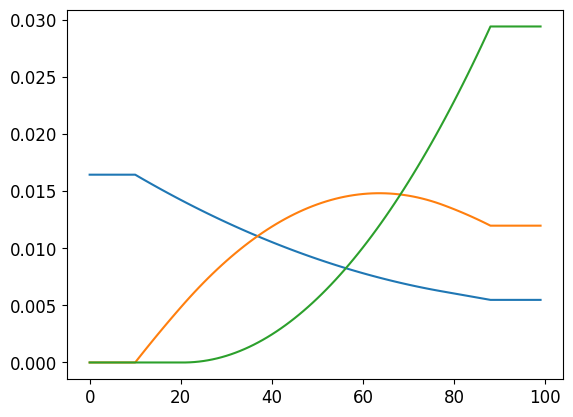

ρ:  [[ 0.5681429   0.00412321 -0.00817488]
 [ 0.00412321  0.45599231  0.02610897]
 [-0.00817488  0.02610897  0.59639057]]


  0%|          | 0/15 [00:00<?, ?it/s]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 39 63

McScan_res:  [39 63]


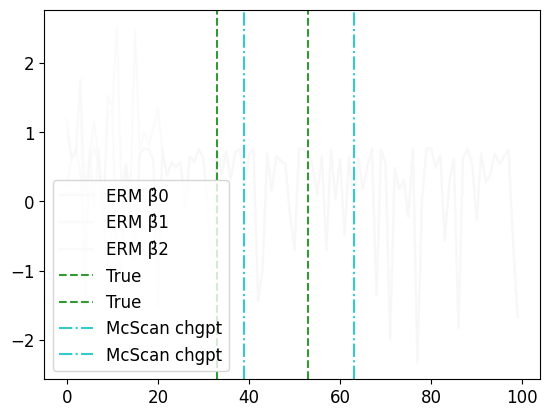

  7%|▋         | 1/15 [00:10<02:22, 10.14s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!


R[write to console]: 



McScan_res:  [-1]


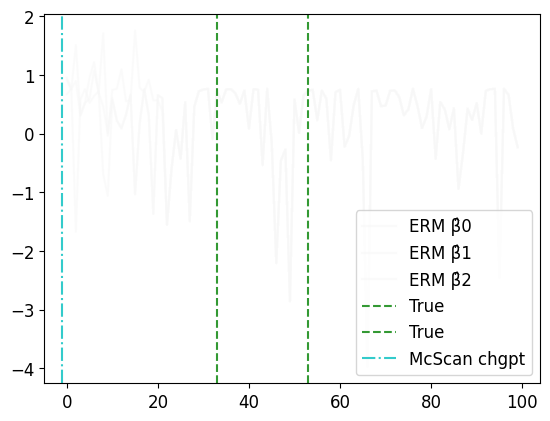

 13%|█▎        | 2/15 [00:12<01:13,  5.67s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 23 70

McScan_res:  [23 70]


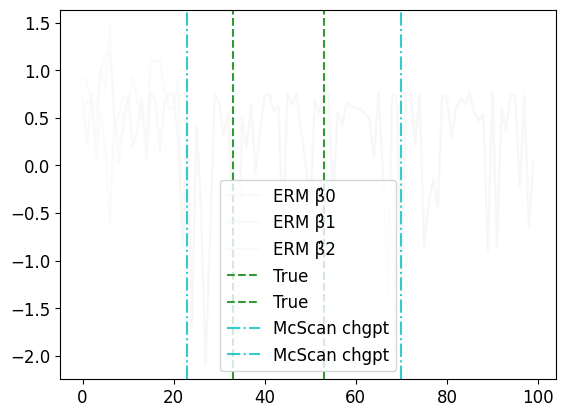

 20%|██        | 3/15 [00:22<01:29,  7.42s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 43 78

McScan_res:  [43 78]


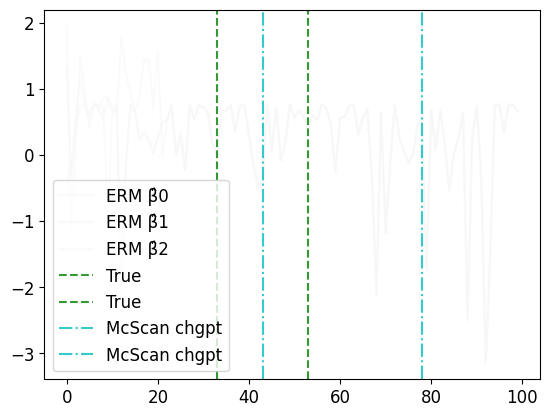

 27%|██▋       | 4/15 [00:31<01:31,  8.30s/it]

Regressing on signal  0


  0%|          | 0/7 [00:32<?, ?it/s]

Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...


KeyboardInterrupt: 

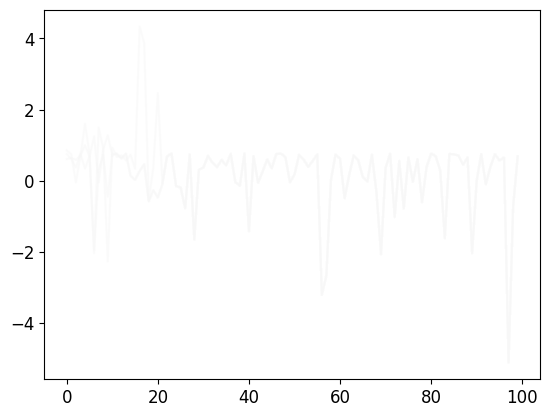

In [36]:
from WERM.config import unif_prior_to_η_ϕ, unif_prior_to_η_ϕ_combinations
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal, SparseGaussianSignal
from WERM.model import *
from WERM.M_est_fixed_point_eqns import *
import WERM
import WERM.gof
import WERM.performance_measures
import WERM.comparison
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
import time
tqdm = partial(tqdm, position=0, leave=True)

np.random.seed(0)

p = 200
L = 3 # num signals. L-1 changepoints

δ_list = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5]
noise_std = 0.1
num_trials = 15

fractional_chgpt_locations = np.array([1/3, 8/15])
# fractional_chgpt_locations = np.array([0.5])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

erm_corr_arr = np.zeros((len(δ_list), num_trials, L))
erm_MSE_arr= np.zeros((len(δ_list), num_trials, L))
ERM_haus_arr = np.zeros((len(δ_list), num_trials))
ERM_size_arr = np.zeros((len(δ_list), num_trials))
ERM_runtime = np.zeros((len(δ_list), num_trials))
DCDP_haus_arr = np.zeros((len(δ_list), num_trials))
DCDP_size_arr = np.zeros((len(δ_list), num_trials))
DCDP_runtime = np.zeros((len(δ_list), num_trials))
McScan_haus_arr = np.zeros((len(δ_list), num_trials))
McScan_size_arr = np.zeros((len(δ_list), num_trials))
McScan_runtime = np.zeros((len(δ_list), num_trials))

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # --- Preliminaries ---
    # Changepoint locations
    # Changepoint locations
    Δ = lambda n: int(n/10)

    # For estimating size
    Lmin = 1
    Lmax = L
    p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    # p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ_combinations(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix

    # For estimating location
    # Lmin = L
    # Lmax = L
    # p_l = None
    # num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix

    ϕ_normalized = ϕ / ϕ.sum(axis = 1)[:, None]
    plt.plot(ϕ_normalized.T)
    plt.show()
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    # Subsampling
    # subsample_factor = 1
    # n_subsampled = int(n/subsample_factor)
    # _, η_arr_subsampled, p_η_arr_subsampled, _ = unif_prior_to_η_ϕ_combinations(Lmin, Lmax, Δ(n_subsampled), n_subsampled, p_l = p_l) # Lxn matrix
    # # _, η_arr_subsampled, p_η_arr_subsampled, _ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n_subsampled), n_subsampled, p_l = p_l) # Lxn matrix
    # η_arr_subsampled = η_arr_subsampled * subsample_factor # Rescale η_arr_subsampled to match η_arr

    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    if fractional_chgpt_locations.size == 0:
        # No chgpt prior
        for ℓ_ in range(L):
            ϕ[ℓ_, :] = np.ones(n)

    # Generate a non-identity covariance matrix
    Σ = np.zeros((p, p))
    for i_ in range(p):
        for j_ in range(p):
            Σ[i_, j_] = 0.00 ** (np.abs(i_ - j_))
    L_chol = scipy.linalg.cholesky(Σ, lower = True)

    # Gaussian Signal Prior
    # γ_squared_over_δ = 8
    # # Design a non-trivial LxL covariance
    # covvy = np.zeros((L, L))
    # for i_ in range(L):
    #     for j_ in range(L):
    #         covvy[i_, j_] = 0.25 ** (np.abs(i_ - j_))
    # # covvy = np.block([[1, 0.4], [0.4, 1]])
    # B̃_cov = γ_squared_over_δ * δ * covvy # keeps the signal power fixed
    # signal_prior = GaussianSignal(B̃_cov)

    # Sparse Gaussian Signal Prior
    α = 0.5 # fraction of nonzeros
    σ_l_arr = np.array([np.sqrt(δ) for ℓ in range(L)]) # signal standard deviation
    signal_prior = SparseGaussianSignal(α, δ, σ_l_arr)

    # Sparse Difference Signal Prior
    # α = 0.25 # fraction of nonzeros
    # # σ_l_arr = np.array([2.5, 2.5]) # signal standard deviation
    # var_β_1 = 1
    # σ_w = 1
    # signal_prior = SparseDiffSignal(var_β_1, σ_w, α, L)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃
    print("ρ: ", ρ)

    for trial_num in tqdm(range(num_trials)): 

        # Generate the observation vector Y
        X = np.random.normal(0, np.sqrt(1/n), (n, p)) @ L_chol.T

        Θ = X @ B̃
        y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()

        # --- Run Weighted ERM --- #
        B̂_erm = np.zeros((p, L))
        β̂_erm_list = [None for ℓ_ in range(L)]

        # Time the execution of the ERM and save it
        start_time_ERM = time.time()
        for ℓ_ in range(L): 
            π = ϕ[ℓ_, :]

            print("Regressing on signal ", ℓ_)
            sample_weight = π
            sk_lin_reg = linear_model.LinearRegression(n_jobs = 2, fit_intercept = False)
            sk_lin_reg.fit(X, y, sample_weight = sample_weight)
            print("Done regressing on signal.")
            β̂_erm = sk_lin_reg.coef_
            β̂_erm_list[ℓ_] = β̂_erm

            ### --- Compute norm squared correlation --- ###
            B̂_erm[:, ℓ_] = β̂_erm
            erm_corr_arr[i, trial_num, ℓ_] = (WERM.norm_sq_corr(β̂_erm, B̃[:, ℓ_])) # For ERM compute once

            ### --- Compute MSE --- ###
            erm_MSE_arr[i, trial_num, ℓ_] = (WERM.MSE(β̂_erm.flatten(), B̃[:, ℓ_]))

        ## Compute Chgpt estimate for WERM
        PAL = ['#e66101', '#fdb863', '#f7f7f7', '#b2abd2', '#5e3c99']
        for ℓ in range(L):
            plt.plot(np.arange(n), (ζ(X @ B̂_erm[:, ℓ]) - np.multiply(y.flatten(), X @ B̂_erm[:, ℓ])), c = PAL[-1 - ℓ_], alpha = 0.5, label="ERM β̂" + str(ℓ))

        print("Optimizing gof erm...")
        opt_chgpt_loc_erm = WERM.gof.lin_reg_opt_chgpt_gof(X @ B̂_erm, y, η_arr, p_η_arr, σ = noise_std, ϵ = 0.005)
        print("WERM chpt estimate: ", opt_chgpt_loc_erm)
        print("Done optimizing gof erm.")
        
        # Save the runtime
        ERM_runtime[i, trial_num] = time.time() - start_time_ERM

        # plot a vertical line at the optimal changepoint location
        [plt.axvline(x=loc, color='r', linestyle='-.', alpha = 0.8, label="ERM chgpt") for loc in opt_chgpt_loc_erm]
        [plt.axvline(x=c, color='g', linestyle='--', alpha = 0.8, label="True") for c in true_chgpt_locations(n)]

        ERM_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(opt_chgpt_loc_erm, true_chgpt_locations(n)))
        ERM_size_arr[i, trial_num] = (len(opt_chgpt_loc_erm[opt_chgpt_loc_erm != -1]))

        ### --- Run DCDP, and record the runtime --- ###
        # start_time_DCDP = time.time()
        # print("Running DCDP...")
        # DCDP_res = np.array(WERM.comparison.DCDP(X, np.array(y), λ_list = [0.1, 1, 5, 10], γ_list = [100, 500, 1000]))
        # print("DCDP_res: ", DCDP_res)
        # DCDP_runtime[i, trial_num] = time.time() - start_time_DCDP
        # # plot a vertical line at the DCDP estimated change point location
        # [plt.axvline(x=loc, color = 'b', linestyle='-.', alpha = 0.8, label="DCDP chgpt") for loc in DCDP_res]
        # DCDP_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(DCDP_res, true_chgpt_locations(n)))
        # DCDP_size_arr[i, trial_num] = (len(DCDP_res[DCDP_res != -1]))

        ### --- Run McScan and record the runtime --- ###
        start_time_McScan = time.time()
        print("Running McScan...")
        try: 
            McScan_res = np.array(WERM.comparison.run_mcscan(X, np.array(y).reshape(-1, 1)))
        except:
            McScan_res = np.array([-1])
        print("McScan_res: ", McScan_res)
        McScan_runtime[i, trial_num] = time.time() - start_time_McScan
        # plot a vertical line at the McScan estimated change point location
        [plt.axvline(x=loc, color='c', linestyle='-.', alpha = 0.8, label="McScan chgpt") for loc in McScan_res]
        McScan_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(McScan_res, true_chgpt_locations(n)))
        McScan_size_arr[i, trial_num] = (len(McScan_res[McScan_res != -1]))

        plt.legend()
        plt.show()

### --- Prepare asymmetric error bars for matplotlib, and ensure that the error bars are not negative --- ###
ERM_lower_err = np.mean(ERM_haus_arr, axis = 1) - np.percentile(ERM_haus_arr, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_haus_arr, 75, axis = 1) - np.mean(ERM_haus_arr, axis = 1)
ERM_haus_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_haus_asymmetric_err[0][ERM_haus_asymmetric_err[0] < 0] = 0
ERM_haus_asymmetric_err[1][ERM_haus_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_haus_arr, axis = 1) - np.percentile(McScan_haus_arr, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_haus_arr, 75, axis = 1) - np.mean(McScan_haus_arr, axis = 1)
McScan_haus_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_haus_asymmetric_err[0][McScan_haus_asymmetric_err[0] < 0] = 0
McScan_haus_asymmetric_err[1][McScan_haus_asymmetric_err[1] < 0] = 0
# DCDP_lower_err = np.mean(DCDP_haus_arr, axis = 1) - np.percentile(DCDP_haus_arr, 25, axis = 1)
# DCDP_upper_err = np.percentile(DCDP_haus_arr, 75, axis = 1) - np.mean(DCDP_haus_arr, axis = 1)
# DCDP_haus_asymmetric_err = [DCDP_lower_err, DCDP_upper_err]
# DCDP_haus_asymmetric_err[0][DCDP_haus_asymmetric_err[0] < 0] = 0
# DCDP_haus_asymmetric_err[1][DCDP_haus_asymmetric_err[1] < 0] = 0

ERM_lower_err = np.mean(ERM_size_arr, axis = 1) - np.percentile(ERM_size_arr, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_size_arr, 75, axis = 1) - np.mean(ERM_size_arr, axis = 1)
ERM_size_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_size_asymmetric_err[0][ERM_size_asymmetric_err[0] < 0] = 0
ERM_size_asymmetric_err[1][ERM_size_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_size_arr, axis = 1) - np.percentile(McScan_size_arr, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_size_arr, 75, axis = 1) - np.mean(McScan_size_arr, axis = 1)
McScan_size_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_size_asymmetric_err[0][McScan_size_asymmetric_err[0] < 0] = 0
McScan_size_asymmetric_err[1][McScan_size_asymmetric_err[1] < 0] = 0
# DCDP_lower_err = np.mean(DCDP_size_arr, axis = 1) - np.percentile(DCDP_size_arr, 25, axis = 1)
# DCDP_upper_err = np.percentile(DCDP_size_arr, 75, axis = 1) - np.mean(DCDP_size_arr, axis = 1)
# DCDP_size_asymmetric_err = [DCDP_lower_err, DCDP_upper_err]
# DCDP_size_asymmetric_err[0][DCDP_size_asymmetric_err[0] < 0] = 0
# DCDP_size_asymmetric_err[1][DCDP_size_asymmetric_err[1] < 0] = 0

ERM_lower_err = np.mean(ERM_runtime, axis = 1) - np.percentile(ERM_runtime, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_runtime, 75, axis = 1) - np.mean(ERM_runtime, axis = 1)
ERM_runtime_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_runtime_asymmetric_err[0][ERM_runtime_asymmetric_err[0] < 0] = 0
ERM_runtime_asymmetric_err[1][ERM_runtime_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_runtime, axis = 1) - np.percentile(McScan_runtime, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_runtime, 75, axis = 1) - np.mean(McScan_runtime, axis = 1)
McScan_runtime_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_runtime_asymmetric_err[0][McScan_runtime_asymmetric_err[0] < 0] = 0
McScan_runtime_asymmetric_err[1][McScan_runtime_asymmetric_err[1] < 0] = 0
# DCDP_lower_err = np.mean(DCDP_runtime, axis = 1) - np.percentile(DCDP_runtime, 25, axis = 1)
# DCDP_upper_err = np.percentile(DCDP_runtime, 75, axis = 1) - np.mean(DCDP_runtime, axis = 1)
# DCDP_runtime_asymmetric_err = [DCDP_lower_err, DCDP_upper_err]
# DCDP_runtime_asymmetric_err[0][DCDP_runtime_asymmetric_err[0] < 0] = 0
# DCDP_runtime_asymmetric_err[1][DCDP_runtime_asymmetric_err[1] < 0] = 0

PAL = ['#1b9e77','#d95f02','#7570b3','#e7298a']
# Sqcorr plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_corr_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# MSE plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_MSE_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
# plt.ylim((0, 2))
plt.xlabel("δ")
plt.ylabel("MSE")
plt.legend()
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(ERM_haus_arr, axis = 1), yerr = ERM_haus_asymmetric_err, label="ERM", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
# plt.errorbar(δ_list, np.mean(DCDP_haus_arr, axis = 1), yerr = DCDP_haus_asymmetric_err, label="DCDP", marker="o", ls="-.", c=PAL[1], alpha = 1.0)
plt.errorbar(δ_list, np.mean(McScan_haus_arr, axis = 1), yerr = McScan_haus_asymmetric_err, label="McScan", marker="o", ls="-.", c=PAL[2], alpha = 1.0)
plt.ylim((0, 0.35))
plt.xlabel("δ")
plt.ylabel("Hausdorff")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Size plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(ERM_size_arr, axis = 1), yerr = ERM_size_asymmetric_err, label="ERM", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
# plt.errorbar(δ_list, np.mean(DCDP_size_arr, axis = 1), yerr = DCDP_size_asymmetric_err, label="DCDP", marker="o", ls="-.", c=PAL[1], alpha = 1.0)
plt.errorbar(δ_list, np.mean(McScan_size_arr, axis = 1), yerr = McScan_size_asymmetric_err, label="McScan", marker="o", ls="-.", c=PAL[2], alpha = 1.0)
plt.ylim((0, L + 1))
plt.xlabel("δ")
plt.ylabel("Size")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Runtime plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(ERM_runtime, axis = 1), yerr = ERM_runtime_asymmetric_err, label="ERM", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
# plt.errorbar(δ_list, np.mean(DCDP_runtime, axis = 1), yerr = DCDP_runtime_asymmetric_err, label="DCDP", marker="o", ls="-.", c=PAL[1], alpha = 1.0)
plt.errorbar(δ_list, np.mean(McScan_runtime, axis = 1), yerr = McScan_runtime_asymmetric_err, label="McScan", marker="o", ls="-.", c=PAL[2], alpha = 1.0)
plt.xlabel("δ")
plt.ylabel("Runtime")
plt.legend()
plt.show()

### Plot against DCDP results from [Arpino et al. 2024]

/Users/gabrielarpino/miniforge3/lib/python3.10/site-packages/numpy/lib/function_base.py:4573: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


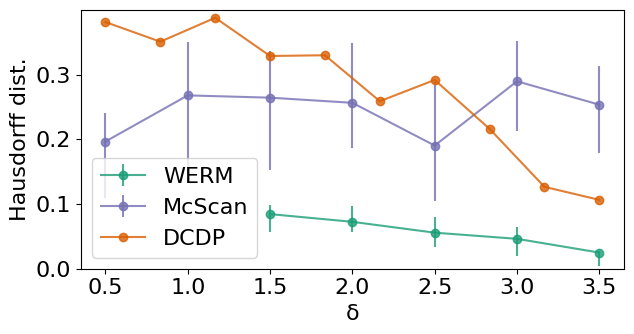

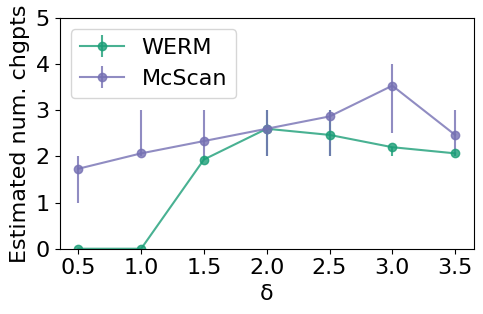

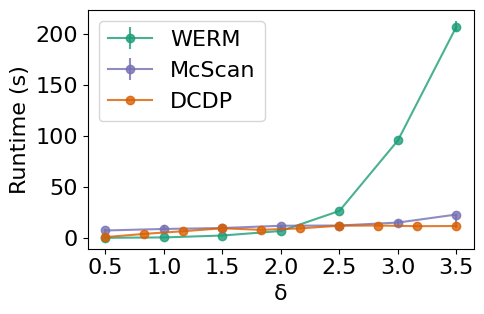

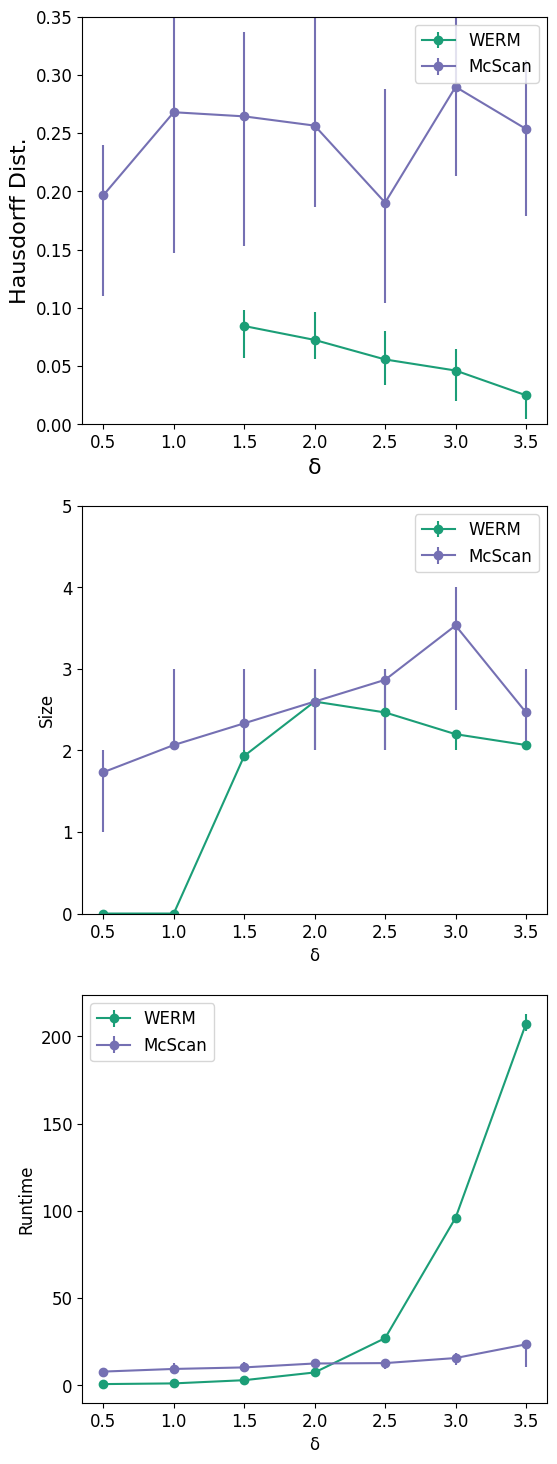

In [30]:
# Save the results
np.save("results/linear_model_comparison/McScan_sparse_signal_comparison/erm_corr_arr_L_" + str(L) + ".npy", erm_corr_arr)
np.save("results/linear_model_comparison/McScan_sparse_signal_comparison/erm_MSE_arr_L_" + str(L) + ".npy", erm_MSE_arr)
np.save("results/linear_model_comparison/McScan_sparse_signal_comparison/ERM_haus_arr_L_" + str(L) + ".npy", ERM_haus_arr)
np.save("results/linear_model_comparison/McScan_sparse_signal_comparison/ERM_size_arr_L_" + str(L) + ".npy", ERM_size_arr)
np.save("results/linear_model_comparison/McScan_sparse_signal_comparison/ERM_runtime_L_" + str(L) + ".npy", ERM_runtime)
np.save("results/linear_model_comparison/McScan_sparse_signal_comparison/DCDP_haus_arr_L_" + str(L) + ".npy", DCDP_haus_arr)
np.save("results/linear_model_comparison/McScan_sparse_signal_comparison/DCDP_size_arr_L_" + str(L) + ".npy", DCDP_size_arr)
np.save("results/linear_model_comparison/McScan_sparse_signal_comparison/McScan_haus_arr_L_" + str(L) + ".npy", McScan_haus_arr)
np.save("results/linear_model_comparison/McScan_sparse_signal_comparison/McScan_size_arr_L_" + str(L) + ".npy", McScan_size_arr)
np.save("results/linear_model_comparison/McScan_sparse_signal_comparison/McScan_runtime_L_" + str(L) + ".npy", McScan_runtime)

### --- Load DCDP results from Arpino et al. 2024 --- ###
δ_list_DCDP = np.array([0.5, 0.83333, 1.166666666667, 1.5, 1.833333333333, 2.166666666667, 2.5, 2.833333333333, 3.166666666667, 3.5])
DCDP_haus_avg = np.array([0.38133333333333, 0.351004016064257, 0.387982832618026, 0.328888888888889, 0.330054644808743, 0.25896843725943, 0.291866666666667, 0.216254416961131, 0.126592943654555, 0.10647619047619])
DCDP_runtime_avg = np.array([1.38509448634254, 4.52350546254052, 7.15471697648366, 10.0103385514683, 8.4857648147477, 9.90291733079487, 12.5548102445073, 12.6848777294159, 12.0718481077088, 12.2109361767769])
DCDP_haus_std = np.array([(0.703407168898341 - 0.0592594977683257)/ 2, (0.560107180750299 - 0.141900851378215)/ 2, (0.570943690879011 - 0.205021974357041)/ 2, (0.39052902332125 - 0.267248754456528)/ 2, (0.416399206650877 - 0.243710082966609)/ 2, (0.402016040419405 - 0.115920834099456)/ 2, (0.38163218838235 - 0.202101144950983)/ 2, (0.336575421682264 - 0.0959334122399975)/ 2, (0.278038584081694 - -0.0248526967725841)/ 2, (0.225645499709057 - -0.012693118756676)/ 2])
DCDP_runtime_std = np.array([(1.47218538515091 - 1.29800358753416)/2, (4.81485347106442 - 4.23215745401662) / 2, (7.58678018505277 - 6.72265376791456)/ 2, (11.0662504871879 - 8.95442661574877)/ 2, (9.11602563920534 - 7.85550399029007)/ 2, (10.8630073840342 - 8.94282727755558)/ 2, (14.1442510944007 - 10.9653693946138)/ 2, (14.7733474790916 - 10.5964079797402)/ 2, (12.943908903235 - 11.1997873121826)/ 2, (13.7346314427387 - 10.6872409108151)/ 2])

### --- Prepare asymmetric error bars for matplotlib, and ensure that the error bars are not negative --- ###
ERM_lower_err = np.mean(ERM_haus_arr, axis = 1) - np.percentile(ERM_haus_arr, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_haus_arr, 75, axis = 1) - np.mean(ERM_haus_arr, axis = 1)
ERM_haus_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_haus_asymmetric_err[0][ERM_haus_asymmetric_err[0] < 0] = 0
ERM_haus_asymmetric_err[1][ERM_haus_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_haus_arr, axis = 1) - np.percentile(McScan_haus_arr, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_haus_arr, 75, axis = 1) - np.mean(McScan_haus_arr, axis = 1)
McScan_haus_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_haus_asymmetric_err[0][McScan_haus_asymmetric_err[0] < 0] = 0
McScan_haus_asymmetric_err[1][McScan_haus_asymmetric_err[1] < 0] = 0

ERM_lower_err = np.mean(ERM_size_arr, axis = 1) - np.percentile(ERM_size_arr, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_size_arr, 75, axis = 1) - np.mean(ERM_size_arr, axis = 1)
ERM_size_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_size_asymmetric_err[0][ERM_size_asymmetric_err[0] < 0] = 0
ERM_size_asymmetric_err[1][ERM_size_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_size_arr, axis = 1) - np.percentile(McScan_size_arr, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_size_arr, 75, axis = 1) - np.mean(McScan_size_arr, axis = 1)
McScan_size_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_size_asymmetric_err[0][McScan_size_asymmetric_err[0] < 0] = 0
McScan_size_asymmetric_err[1][McScan_size_asymmetric_err[1] < 0] = 0

ERM_lower_err = np.mean(ERM_runtime, axis = 1) - np.percentile(ERM_runtime, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_runtime, 75, axis = 1) - np.mean(ERM_runtime, axis = 1)
ERM_runtime_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_runtime_asymmetric_err[0][ERM_runtime_asymmetric_err[0] < 0] = 0
ERM_runtime_asymmetric_err[1][ERM_runtime_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_runtime, axis = 1) - np.percentile(McScan_runtime, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_runtime, 75, axis = 1) - np.mean(McScan_runtime, axis = 1)
McScan_runtime_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_runtime_asymmetric_err[0][McScan_runtime_asymmetric_err[0] < 0] = 0
McScan_runtime_asymmetric_err[1][McScan_runtime_asymmetric_err[1] < 0] = 0

### --- Replot the figures individually --- ###
δ_arr = np.array([δ_list for _ in range(num_trials)])
# Hausdorff plots
fig = plt.figure(figsize = (6.5, 3.5))
cmap = plt.get_cmap('RdBu')
plt.rcParams.update({'font.size': 12})
plt.errorbar(δ_list, np.mean(ERM_haus_arr, axis = 1), yerr = ERM_haus_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 0.8)
plt.errorbar(δ_list, np.mean(McScan_haus_arr, axis = 1), yerr = McScan_haus_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 0.8)
plt.errorbar(δ_list_DCDP, DCDP_haus_avg, yerr = None, label="DCDP", marker="o", ls="-", c=PAL[1], alpha = 0.8)
plt.ylim((0, 0.4))
plt.xlabel("δ", fontsize=16)
plt.ylabel("Hausdorff dist.", fontsize=16)
plt.xticks(fontsize=16)
plt.yticks([0, 0.1, 0.2, 0.3], fontsize=16)
plt.legend(prop={'size': 16}, loc='lower left')
fig.tight_layout()
plt.savefig("figures/linear_model_comparison/McScan_sparse_signal_comparison/linear_model_comparison_haus" + str(L) + "_Lstar" + str(fractional_chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Size plots
fig = plt.figure(figsize = (5, 3.3))
cmap = plt.get_cmap('RdBu')
plt.rcParams.update({'font.size': 12})
plt.errorbar(δ_list, np.mean(ERM_size_arr, axis = 1), yerr = ERM_size_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 0.8)
plt.errorbar(δ_list, np.mean(McScan_size_arr, axis = 1), yerr = McScan_size_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 0.8)
plt.ylim((0, L + 1))
plt.xlabel("δ", fontsize=16)
plt.ylabel("Estimated num. chgpts", fontsize=16)
plt.legend(prop={'size': 16})
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
fig.tight_layout()
plt.savefig("figures/linear_model_comparison/McScan_sparse_signal_comparison/linear_model_comparison_size" + str(L) + "_Lstar" + str(fractional_chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Runtime plots
fig = plt.figure(figsize = (5, 3.3))
cmap = plt.get_cmap('RdBu')
plt.rcParams.update({'font.size': 12})
plt.errorbar(δ_list, np.mean(ERM_runtime, axis = 1), yerr = ERM_runtime_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 0.8)
plt.errorbar(δ_list, np.mean(McScan_runtime, axis = 1), yerr = McScan_runtime_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 0.8)
plt.errorbar(δ_list_DCDP, DCDP_runtime_avg, yerr = None, label="DCDP", marker="o", ls="-", c=PAL[1], alpha = 0.8)
plt.xlabel("δ", fontsize=16)
plt.ylabel("Runtime (s)", fontsize=16)
plt.legend(prop={'size': 16})
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
fig.tight_layout()
plt.savefig("figures/linear_model_comparison/McScan_sparse_signal_comparison/linear_model_comparison_runtime" + str(L) + "_Lstar" + str(fractional_chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Plot the above three figures on top of each other as subplots
fig, axs = plt.subplots(3, 1, figsize=(6, 18))

# Hausdorff estimation plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
axs[0].errorbar(δ_list, np.mean(ERM_haus_arr, axis = 1), yerr = ERM_haus_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 1.0)
axs[0].errorbar(δ_list, np.mean(McScan_haus_arr, axis = 1), yerr = McScan_haus_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 1.0)
axs[0].set_ylim((0, 0.35))
axs[0].set_xlabel("δ", fontsize=16)
axs[0].set_ylabel("Hausdorff Dist.", fontsize=16)
axs[0].legend()

# Hausdorff size plots
axs[1].errorbar(δ_list, np.mean(ERM_size_arr, axis = 1), yerr = ERM_size_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 1.0)
axs[1].errorbar(δ_list, np.mean(McScan_size_arr, axis = 1), yerr = McScan_size_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 1.0)
axs[1].set_ylim((0, L + 1))
axs[1].set_xlabel("δ")
axs[1].set_ylabel("Size")
axs[1].legend()

# Runtime plots
axs[2].errorbar(δ_list, np.mean(ERM_runtime, axis = 1), yerr = ERM_runtime_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 1.0)
axs[2].errorbar(δ_list, np.mean(McScan_runtime, axis = 1), yerr = McScan_runtime_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 1.0)
axs[2].set_xlabel("δ")
axs[2].set_ylabel("Runtime")
axs[2].legend()
plt.savefig("figures/linear_model_comparison/McScan_sparse_signal_comparison/linear_model_comparison_L_" + str(L) + ".pdf")

# Save the figure as a tikz file, and use a workaround to make the legend work
import tikzplotlib
def tikzplotlib_fix_ncols(obj):
    """
    workaround for matplotlib 3.6 renamed legend's _ncol to _ncols, which breaks tikzplotlib
    """
    if hasattr(obj, "_ncols"):
        obj._ncol = obj._ncols
    for child in obj.get_children():
        tikzplotlib_fix_ncols(child)
tikzplotlib_fix_ncols(fig)
tikzplotlib.save("figures/linear_model_comparison/McScan_sparse_signal_comparison/linear_model_comparison_L_" + str(L) + ".tex")


plt.show()



### Load the data and re-plot

/Users/gabrielarpino/miniforge3/lib/python3.10/site-packages/numpy/lib/function_base.py:4573: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


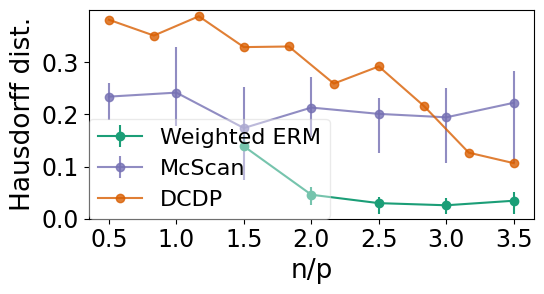

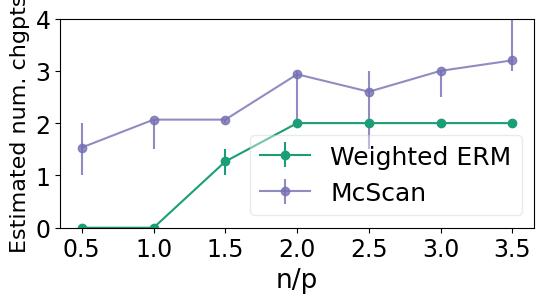

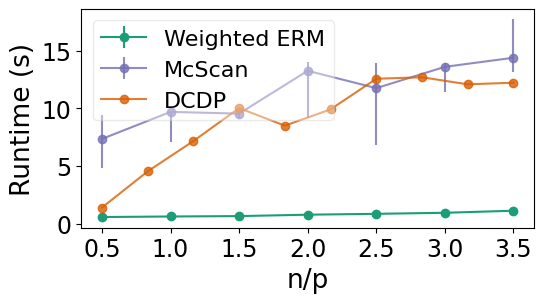

In [19]:
# Set hyperparameters
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
import time
tqdm = partial(tqdm, position=0, leave=True)

np.random.seed(0)

p = 200
L = 3 # num signals. L-1 changepoints

δ_list = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5]
noise_std = 0.1
num_trials = 15

fractional_chgpt_locations = np.array([1/3, 8/15])
PAL = ['#1b9e77','#d95f02','#7570b3','#e7298a']

# Load the data and re-plot

erm_corr_arr = np.load("results/linear_model_comparison/McScan_sparse_signal_comparison/erm_corr_arr_L_" + str(L) + ".npy")
erm_MSE_arr = np.load("results/linear_model_comparison/McScan_sparse_signal_comparison/erm_MSE_arr_L_" + str(L) + ".npy")
ERM_haus_arr = np.load("results/linear_model_comparison/McScan_sparse_signal_comparison/ERM_haus_arr_L_" + str(L) + ".npy")
ERM_size_arr = np.load("results/linear_model_comparison/McScan_sparse_signal_comparison/ERM_size_arr_L_" + str(L) + ".npy")
ERM_runtime = np.load("results/linear_model_comparison/McScan_sparse_signal_comparison/ERM_runtime_L_" + str(L) + ".npy")
DCDP_haus_arr = np.load("results/linear_model_comparison/McScan_sparse_signal_comparison/DCDP_haus_arr_L_" + str(L) + ".npy")
DCDP_size_arr = np.load("results/linear_model_comparison/McScan_sparse_signal_comparison/DCDP_size_arr_L_" + str(L) + ".npy")
McScan_haus_arr = np.load("results/linear_model_comparison/McScan_sparse_signal_comparison/McScan_haus_arr_L_" + str(L) + ".npy")
McScan_size_arr = np.load("results/linear_model_comparison/McScan_sparse_signal_comparison/McScan_size_arr_L_" + str(L) + ".npy")
McScan_runtime = np.load("results/linear_model_comparison/McScan_sparse_signal_comparison/McScan_runtime_L_" + str(L) + ".npy")

### --- Load DCDP results from Arpino et al. 2024 (Inferring Change Points in High-Dimensional Linear Regression via Approximate Message Passing) --- ###
δ_list_DCDP = np.array([0.5, 0.83333, 1.166666666667, 1.5, 1.833333333333, 2.166666666667, 2.5, 2.833333333333, 3.166666666667, 3.5])
DCDP_haus_avg = np.array([0.38133333333333, 0.351004016064257, 0.387982832618026, 0.328888888888889, 0.330054644808743, 0.25896843725943, 0.291866666666667, 0.216254416961131, 0.126592943654555, 0.10647619047619])
DCDP_runtime_avg = np.array([1.38509448634254, 4.52350546254052, 7.15471697648366, 10.0103385514683, 8.4857648147477, 9.90291733079487, 12.5548102445073, 12.6848777294159, 12.0718481077088, 12.2109361767769])
DCDP_haus_std = np.array([(0.703407168898341 - 0.0592594977683257)/ 2, (0.560107180750299 - 0.141900851378215)/ 2, (0.570943690879011 - 0.205021974357041)/ 2, (0.39052902332125 - 0.267248754456528)/ 2, (0.416399206650877 - 0.243710082966609)/ 2, (0.402016040419405 - 0.115920834099456)/ 2, (0.38163218838235 - 0.202101144950983)/ 2, (0.336575421682264 - 0.0959334122399975)/ 2, (0.278038584081694 - -0.0248526967725841)/ 2, (0.225645499709057 - -0.012693118756676)/ 2])
DCDP_runtime_std = np.array([(1.47218538515091 - 1.29800358753416)/2, (4.81485347106442 - 4.23215745401662) / 2, (7.58678018505277 - 6.72265376791456)/ 2, (11.0662504871879 - 8.95442661574877)/ 2, (9.11602563920534 - 7.85550399029007)/ 2, (10.8630073840342 - 8.94282727755558)/ 2, (14.1442510944007 - 10.9653693946138)/ 2, (14.7733474790916 - 10.5964079797402)/ 2, (12.943908903235 - 11.1997873121826)/ 2, (13.7346314427387 - 10.6872409108151)/ 2])

### --- Prepare asymmetric error bars for matplotlib, and ensure that the error bars are not negative --- ###
ERM_lower_err = np.mean(ERM_haus_arr, axis = 1) - np.percentile(ERM_haus_arr, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_haus_arr, 75, axis = 1) - np.mean(ERM_haus_arr, axis = 1)
ERM_haus_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_haus_asymmetric_err[0][ERM_haus_asymmetric_err[0] < 0] = 0
ERM_haus_asymmetric_err[1][ERM_haus_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_haus_arr, axis = 1) - np.percentile(McScan_haus_arr, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_haus_arr, 75, axis = 1) - np.mean(McScan_haus_arr, axis = 1)
McScan_haus_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_haus_asymmetric_err[0][McScan_haus_asymmetric_err[0] < 0] = 0
McScan_haus_asymmetric_err[1][McScan_haus_asymmetric_err[1] < 0] = 0

ERM_lower_err = np.mean(ERM_size_arr, axis = 1) - np.percentile(ERM_size_arr, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_size_arr, 75, axis = 1) - np.mean(ERM_size_arr, axis = 1)
ERM_size_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_size_asymmetric_err[0][ERM_size_asymmetric_err[0] < 0] = 0
ERM_size_asymmetric_err[1][ERM_size_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_size_arr, axis = 1) - np.percentile(McScan_size_arr, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_size_arr, 75, axis = 1) - np.mean(McScan_size_arr, axis = 1)
McScan_size_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_size_asymmetric_err[0][McScan_size_asymmetric_err[0] < 0] = 0
McScan_size_asymmetric_err[1][McScan_size_asymmetric_err[1] < 0] = 0

ERM_lower_err = np.mean(ERM_runtime, axis = 1) - np.percentile(ERM_runtime, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_runtime, 75, axis = 1) - np.mean(ERM_runtime, axis = 1)
ERM_runtime_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_runtime_asymmetric_err[0][ERM_runtime_asymmetric_err[0] < 0] = 0
ERM_runtime_asymmetric_err[1][ERM_runtime_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_runtime, axis = 1) - np.percentile(McScan_runtime, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_runtime, 75, axis = 1) - np.mean(McScan_runtime, axis = 1)
McScan_runtime_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_runtime_asymmetric_err[0][McScan_runtime_asymmetric_err[0] < 0] = 0
McScan_runtime_asymmetric_err[1][McScan_runtime_asymmetric_err[1] < 0] = 0

### --- Replot the figures individually --- ###
δ_arr = np.array([δ_list for _ in range(num_trials)])
# Hausdorff plots
# fig = plt.figure(figsize = (6.5, 3.5))
# fig = plt.figure(figsize = (6.0, 4.0))
fig = plt.figure(figsize = (5.6, 3.1))
cmap = plt.get_cmap('RdBu')
plt.rcParams.update({'font.size': 12})
plt.errorbar(δ_list, np.mean(ERM_haus_arr, axis = 1), yerr = ERM_haus_asymmetric_err, label="Weighted ERM", marker="o", ls="-", c=PAL[0], alpha = 1.0)
plt.errorbar(δ_list, np.mean(McScan_haus_arr, axis = 1), yerr = McScan_haus_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 0.8)
plt.errorbar(δ_list_DCDP, DCDP_haus_avg, yerr = None, label="DCDP", marker="o", ls="-", c=PAL[1], alpha = 0.8)
plt.ylim((0, 0.4))
plt.xlabel("n/p", fontsize=19)
plt.ylabel("Hausdorff dist.", fontsize=19)
plt.xticks(fontsize=17)
plt.yticks([0, 0.1, 0.2, 0.3], fontsize=17)
# plt.legend(prop={'size': 15}, loc='best')
# plt.legend(prop={'size': 16}, loc='upper right')
plt.legend(prop={'size': 16}, loc=(0.00005, 0.00005), fancybox=True, framealpha=0.4)
fig.tight_layout()
plt.savefig("figures/linear_model_comparison/McScan_sparse_signal_comparison/linear_model_comparison_haus_L" + str(L) + "_Lstar" + str(fractional_chgpt_locations.shape[0]) + "_resize_alt.pdf")
plt.show()

# Size plots
# fig = plt.figure(figsize = (5, 3.3))
# fig = plt.figure(figsize = (5.3, 3.6))
fig = plt.figure(figsize = (5.6, 3.2))
# fig = plt.figure(figsize = (6.0, 4.0))
cmap = plt.get_cmap('RdBu')
plt.rcParams.update({'font.size': 12})
plt.errorbar(δ_list, np.mean(ERM_size_arr, axis = 1), yerr = ERM_size_asymmetric_err, label="Weighted ERM", marker="o", ls="-", c=PAL[0], alpha = 1.0)
plt.errorbar(δ_list, np.mean(McScan_size_arr, axis = 1), yerr = McScan_size_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 0.8)
plt.ylim((0, L + 1))
plt.xlabel("n/p", fontsize=19)
plt.ylabel("Estimated num. chgpts", fontsize=16)
plt.legend(prop={'size': 18}, fancybox = True, framealpha = 0.4)
plt.xticks(fontsize=17)
plt.yticks(fontsize=17)
fig.tight_layout()
plt.savefig("figures/linear_model_comparison/McScan_sparse_signal_comparison/linear_model_comparison_size_L" + str(L) + "_Lstar" + str(fractional_chgpt_locations.shape[0]) + "_resize_alt.pdf")
plt.show()

# Runtime plots
# fig = plt.figure(figsize = (5.3, 3.6))
fig = plt.figure(figsize = (5.6, 3.2))
# fig = plt.figure(figsize = (6.0, 4.0))
cmap = plt.get_cmap('RdBu')
plt.rcParams.update({'font.size': 12})
plt.errorbar(δ_list, np.mean(ERM_runtime, axis = 1), yerr = ERM_runtime_asymmetric_err, label="Weighted ERM", marker="o", ls="-", c=PAL[0], alpha = 1.0)
plt.errorbar(δ_list, np.mean(McScan_runtime, axis = 1), yerr = McScan_runtime_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 0.8)
plt.errorbar(δ_list_DCDP, DCDP_runtime_avg, yerr = None, label="DCDP", marker="o", ls="-", c=PAL[1], alpha = 0.8)
plt.xlabel("n/p", fontsize=19)
plt.ylabel("Runtime (s)", fontsize=19)
plt.legend(prop={'size': 16}, fancybox = True, framealpha = 0.4)
plt.xticks(fontsize=17)
plt.yticks(fontsize=17)
fig.tight_layout()
plt.savefig("figures/linear_model_comparison/McScan_sparse_signal_comparison/linear_model_comparison_runtime_L" + str(L) + "_Lstar" + str(fractional_chgpt_locations.shape[0]) + "_resize_alt.pdf")
plt.show()